# SAE "Analyse automatique de données" -- Notebook 4 : régression linéaire

Dans ce notebook, vous devez :
1. Effectuer des expérimentations pour optimiser les paramètres du modèle de régression linéaire ;
2. Rédiger une synthèse pour justifier des pré-traitements effectués et des valeurs des paramètres obtenus pour vos modèles de régression. Vous concluerez sur le meilleur choix des pré-traitements et des paramètres de votre ou vos modèles.

	
Vous pouvez également tout d'abord considérer un sous-ensemble de votre ensemble d'apprentissage, pour mettre au point chacune de vos expérimentations.
			


## Modules python utilisés

In [96]:

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_squared_error, r2_score 
from sklearn.model_selection import GridSearchCV
import math
import spacy
import numpy as np


## 1. Régression linéaire

In [85]:
#Df d'apprentissage
x_train = pd.read_csv('data/train_test/x_train.csv',  index_col=0)
y_train = pd.read_csv('data/train_test/y_train.csv',  index_col=0)

#Df de test
x_test = pd.read_csv('data/train_test/x_test.csv',  index_col=0)
y_test = pd.read_csv('data/train_test/y_test.csv',  index_col=0)


In [ ]:
x_train = x_train.dropna(subset=['text_']).copy()
y_train = y_train.loc[x_train.index].copy()

x_test = x_test.dropna(subset=['text_']).copy()
y_test = y_test.loc[x_test.index].copy()

x_train['text_'] = x_train['text_'].astype(str)
x_test['text_'] = x_test['text_'].astype(str)

nlp = spacy.load("en_core_web_sm")

def cleanData(texts):
    processed_texts = []
    for doc in nlp.pipe(texts, disable=["ner", "parser"]):
        try:
            tokens = [
                token.lemma_.lower() for token in doc
                if not token.is_stop and not token.is_punct 
                and token.pos_ in ["ADJ","ADV","VERB","NOUN"]
            ]
            processed_texts.append(" ".join(tokens))
        except Exception as e :
            print(f"Erreur sur la phrase : {e}")
    return processed_texts
    
x_train['text_'] = cleanData(x_train['text_'])
x_test['text_'] = cleanData(x_test['text_'])

x_train['text_'] = x_train['text_'].replace("", np.nan)
x_test['text_'] = x_test['text_'].replace("", np.nan)

x_train = x_train.dropna(subset=['text_']).copy()
x_test = x_test.dropna(subset=['text_']).copy()

y_train = y_train.loc[x_train.index]
y_test = y_test.loc[x_test.index]

### 1.1 Régression avec le texte - Linear Regression

Processeur : drop
Fitting 5 folds for each of 18 candidates, totalling 90 fits
Meilleurs paramètres : {'preprocessor__review__max_features': 2000, 'preprocessor__review__min_df': 20, 'preprocessor__review__ngram_range': (1, 1)}
Meilleure RMSE : 1.625
Mse: 1.6214252076397333
RMSE: 1.273351957488476
R2 Score: 0.09669180180757886


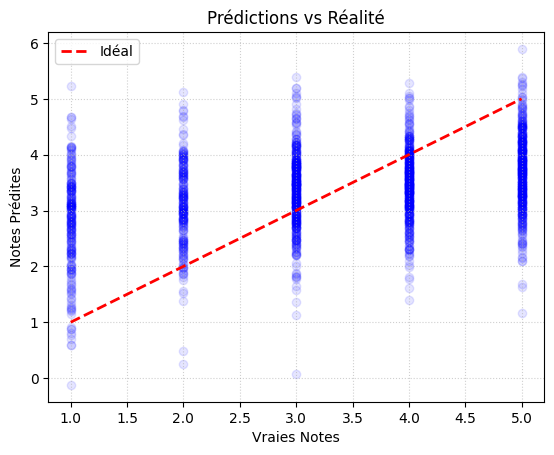

In [98]:
# On défini les différents transformeurs 
processeur = ColumnTransformer(
    remainder='drop',
    transformers=[
        ('review', TfidfVectorizer(
            max_features=2000, # Garder les X termes plus importants
            min_df=20, # Ignorer les mots avec une rareté inférieur à 20
            ngram_range=(1,1), # Capte les expressions de 2 mots monogramme et bigramme
            stop_words='english',
            use_idf=True), 
         'text_'),
    ]
)

print(f"Processeur : {processeur.remainder}")

model = Pipeline([
    ('preprocessor', processeur),
    ('classifier', LinearRegression())
])

param_grid = {
    'preprocessor__review__max_features': [2000, 5000, 10000],
    'preprocessor__review__min_df': [5, 10, 20],
    'preprocessor__review__ngram_range': [(1, 1), (1, 2)],
}

reg_search_linear_regression = GridSearchCV(
    model, 
    param_grid, 
    cv=5,                   # Validation croisée en 5 plis
    scoring='neg_mean_squared_error', # Score pour la régression
    n_jobs=-1,              # Utilise tous les processeurs
    verbose=1
)

reg_search_linear_regression.fit(x_train, y_train)

print(f"Meilleurs paramètres : {reg_search_linear_regression.best_params_}")
print(f"Meilleure RMSE : {-reg_search_linear_regression.best_score_:.3f}")


prediction_linear_regression = reg_search_linear_regression.best_estimator_.predict(x_test)

mse = mean_squared_error(y_test,prediction_linear_regression)

print(f"Mse: {mse}")
print(f"RMSE: {math.sqrt(mse)}")
print(f"R2 Score: {r2_score(y_test,prediction_linear_regression)}")
plt.scatter(y_test, prediction_linear_regression, color='blue', alpha=0.1)

plt.plot([1, 5], [1, 5], color='red', linestyle='--', linewidth=2, label='Idéal')

plt.title('Prédictions vs Réalité')
plt.xlabel('Vraies Notes')
plt.ylabel('Notes Prédites')
plt.legend()
plt.grid(True, linestyle=':', alpha=0.6)


### 1.3 Régression avec le texte - Ridge

Processeur : drop
Fitting 5 folds for each of 108 candidates, totalling 540 fits
Meilleurs paramètres : {'classifier__alpha': 10, 'preprocessor__review__max_features': 5000, 'preprocessor__review__min_df': 20, 'preprocessor__review__ngram_range': (1, 2)}
Meilleure RMSE : 1.479
Mse: 1.4341674518028418
RMSE: 1.197567305750638
R2 Score: 0.20101450829171463


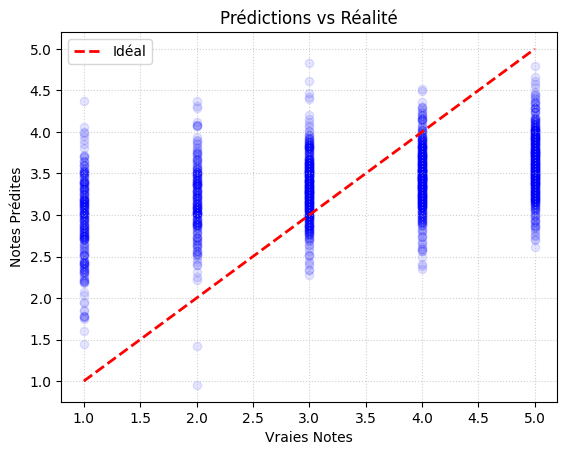

In [88]:
# On défini les différents transformeurs 
processeur = ColumnTransformer(
    remainder='drop',
    transformers=[
        ('review', TfidfVectorizer(
            max_features=2000, # Garder les X termes plus importants
            min_df=20, # Ignorer les mots avec une rareté inférieur à 20
            ngram_range=(1,1), # Capte les expressions de 2 mots monogramme et bigramme
            stop_words='english',
            use_idf=True), 
         'text_'),
    ]
)

print(f"Processeur : {processeur.remainder}")

model = Pipeline([
    ('preprocessor', processeur),
    ('classifier', Ridge())
])

param_grid = {
    'preprocessor__review__max_features': [2000, 5000, 10000],
    'preprocessor__review__min_df': [5, 10, 20],
    'preprocessor__review__ngram_range': [(1, 1), (1, 2)],
    'classifier__alpha':[0.001, 0.01, 0.1, 0, 1, 10]
}

reg_search = GridSearchCV(
    model, 
    param_grid, 
    cv=5,                   # Validation croisée en 5 plis
    scoring='neg_mean_squared_error', # Score pour la régression
    n_jobs=-1,              # Utilise tous les processeurs
    verbose=1
)

reg_search.fit(x_train, y_train)

print(f"Meilleurs paramètres : {reg_search.best_params_}")
print(f"Meilleure RMSE : {-reg_search.best_score_:.3f}")


prediction = reg_search.best_estimator_.predict(x_test)

mse = mean_squared_error(y_test,prediction)

print(f"Mse: {mse}")
print(f"RMSE: {math.sqrt(mse)}")
print(f"R2 Score: {r2_score(y_test,prediction)}")
plt.scatter(y_test, prediction, color='blue', alpha=0.1)

plt.plot([1, 5], [1, 5], color='red', linestyle='--', linewidth=2, label='Idéal')

plt.title('Prédictions vs Réalité')
plt.xlabel('Vraies Notes')
plt.ylabel('Notes Prédites')
plt.legend()
plt.grid(True, linestyle=':', alpha=0.6)


### 1.3.1 Analyse des mots les plus utilisés

In [89]:
best_model = reg_search.best_estimator_
vectorizer = best_model.named_steps['preprocessor'].transformers_[0][1]
ridge_clf = best_model.named_steps['classifier']

feature_names = vectorizer.get_feature_names_out()

df_coeffs = pd.DataFrame({
    'mot': feature_names,
    'coefficient': ridge_clf.coef_
})

print("--- Mots les plus associés à une note ÉLEVÉE ---")
print(df_coeffs.sort_values(by='coefficient', ascending=False).head(10))

print("\n--- Mots les plus associés à une note FAIBLE ---")
print(df_coeffs.sort_values(by='coefficient', ascending=True).head(10))

--- Mots les plus associés à une note ÉLEVÉE ---
            mot  coefficient
1342       love     2.075975
960       great     1.642223
110     awesome     1.240498
1629    perfect     1.181056
656        easy     1.014348
56      amazing     0.968940
727     exactly     0.965966
729   excellent     0.938779
695       enjoy     0.821248
1516       nice     0.805915

--- Mots les plus associés à une note FAIBLE ---
               mot  coefficient
1932        return    -2.007973
2510         waste    -1.721167
601   disappointed    -1.566669
1693          poor    -1.401827
1166          junk    -1.321225
2336      terrible    -1.299693
254          break    -1.238403
118            bad    -1.174978
1080      horrible    -1.098503
374          cheap    -1.045677


### 1.4 Lasso

Processeur : drop
Fitting 5 folds for each of 126 candidates, totalling 630 fits
Meilleurs paramètres : {'classifier__alpha': 0.0001, 'preprocessor__review__max_features': 2000, 'preprocessor__review__min_df': 20, 'preprocessor__review__ngram_range': (1, 2)}
Meilleure RMSE : 1.500
Mse: 1.446391701856833
RMSE: 1.2026602603631804
R2 Score: 0.19420428649517651


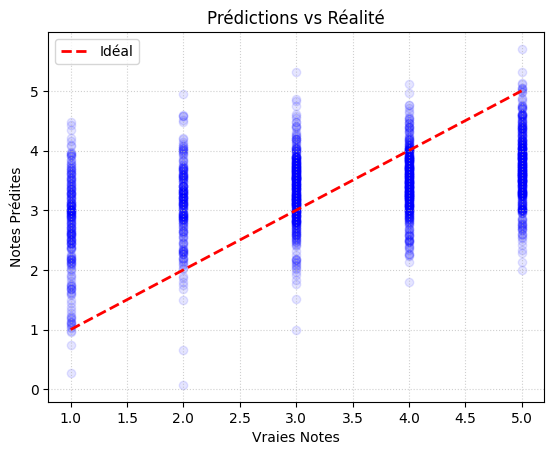

In [90]:
# On défini les différents transformeurs 
processeur = ColumnTransformer(
    remainder='drop',
    transformers=[
        ('review', TfidfVectorizer(
            max_features=2000, # Garder les X termes plus importants
            min_df=20, # Ignorer les mots avec une rareté inférieur à 20
            ngram_range=(1,1), # Capte les expressions de 2 mots monogramme et bigramme
            stop_words='english',
            use_idf=True), 
         'text_'),
    ]
)

print(f"Processeur : {processeur.remainder}")

model = Pipeline([
    ('preprocessor', processeur),
    ('classifier', Lasso())
])

param_grid = {
    'preprocessor__review__max_features': [2000, 5000, 10000],
    'preprocessor__review__min_df': [5, 10, 20],
    'preprocessor__review__ngram_range': [(1, 1), (1, 2)],
    'classifier__alpha': [1e-5, 1e-4, 1e-3, 1e-2, 0.1, 1, 10]
}

reg_search = GridSearchCV(
    model, 
    param_grid, 
    cv=5,                   # Validation croisée en 5 plis
    scoring='neg_mean_squared_error', # Score pour la régression
    n_jobs=-1,              # Utilise tous les processeurs
    verbose=1
)

reg_search.fit(x_train, y_train)

print(f"Meilleurs paramètres : {reg_search.best_params_}")
print(f"Meilleure RMSE : {-reg_search.best_score_:.3f}")


prediction = reg_search.best_estimator_.predict(x_test)

mse = mean_squared_error(y_test,prediction)

print(f"Mse: {mse}")
print(f"RMSE: {math.sqrt(mse)}")
print(f"R2 Score: {r2_score(y_test,prediction)}")
plt.scatter(y_test, prediction, color='blue', alpha=0.1)

plt.plot([1, 5], [1, 5], color='red', linestyle='--', linewidth=2, label='Idéal')

plt.title('Prédictions vs Réalité')
plt.xlabel('Vraies Notes')
plt.ylabel('Notes Prédites')
plt.legend()
plt.grid(True, linestyle=':', alpha=0.6)


## 2. Synthèse des expérimentations et des résultats obtenus